In [1]:
import csv
import biom
from biom import Table
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score

In [2]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.gridspec import GridSpec
from sklearn.metrics import r2_score, mean_absolute_error

In [3]:
from skbio.stats import subsample_counts

# Methods

## Microbiome data and sample curation

Bacterial community profiles derived from 16S rRNA gene amplicon sequencing were
aggregated across multiple independent studies (BioProjects) and stored as a
feature (BIOM) count table together with harmonized sample metadata. Samples were retained
for analysis only if they had a valid, positive host age (`age_cleaned` > 0), a
non-missing oral collection site, and a defined site annotation (samples labeled
as "other" were excluded). After this initial curation, [20,314] oral samples
were available across six oral sites (saliva, tooth, tongue, oral mucosa, oral
swab, and gingiva).

## Feature filtering and normalization

Prior to modeling, the feature table was matched to the curated
metadata by retaining only samples present in both, and empty features and
samples were removed. Two quality-control filters were then applied: (i) a
prevalence filter that retained genera detected in more than 50 samples, and
(ii) a sequencing-depth filter that retained samples with more than 1,000 total
reads. Within each cross-validation training set (see below), the feature
vocabulary was defined by the OTU observed in the training samples, and
counts were converted to per-sample relative abundances (each sample's counts
divided by its total). Test samples were represented using the same feature set
as their corresponding training set, with genera absent from a given sample set
to zero.

## Study selection

Age prediction was performed separately for each of four oral sites with
sufficient data: saliva, tooth, tongue, and oral mucosa. For each site, only
studies (BioProjects) that contributed more than 10 healthy-control samples were
retained, yielding 49, 12, 4, and 5 eligible studies for saliva, tooth, tongue,
and oral mucosa, respectively. This threshold ensured that each study entering
cross-validation contributed enough samples to provide a stable, site-specific
estimate.

## Age-prediction model

Host age was modeled as a continuous outcome using a Random Forest regressor
(`RandomForestRegressor`; scikit-learn). All models were trained with
500 trees (`n_estimators` = 500) and a fixed random seed
(`random_state` = 42) to ensure reproducibility; remaining hyperparameters were
left at their scikit-learn default values. Genus-level relative abundances were
used as input features and chronological age (in years) as the regression
target.

## Study-stratified (leave-studies-out) cross-validation

To evaluate generalization to previously unseen cohorts rather than to unseen
samples from cohorts already represented in training, a study-stratified
("leave-studies-out") cross-validation scheme was used. For each oral site, the
eligible studies were partitioned into folds using K-fold cross-validation over
studies (`KFold`, shuffled, `random_state` = 42), with the number of folds set
per site (five folds for saliva, tooth, and oral mucosa; four folds for tongue).
In each fold, samples from a subset of studies formed the training set and
samples from the held-out studies formed the test set, so that no study
contributed samples to both the training and test partitions of the same fold.

Within each fold, the training set comprised only healthy-control samples from
the training studies. To avoid extrapolation beyond the observed training range,
the test set was restricted to samples whose age fell within the minimum and
maximum ages of the corresponding training set; folds for which no test samples
remained after this restriction were excluded. Feature selection, relative-
abundance normalization, and feature alignment were performed independently
within each fold using only the training data, to prevent information leakage
across the train–test boundary. For every held-out sample, the trained model
produced a predicted age, and the prediction error was recorded as the
difference between predicted and true age.

## Model evaluation

Model performance was assessed by pooling the out-of-fold predictions across all
folds for each oral site and comparing predicted with true age, restricted to
healthy-control samples. Two performance metrics were computed: the coefficient
of determination (R²), quantifying the proportion of variance in age explained
by the predictions, and the mean absolute error (MAE), quantifying the average
absolute deviation between predicted and true age in years. Predicted versus
true age was visualized as scatter plots, each annotated with the corresponding
R² and MAE and overlaid with a least-squares linear fit and the 1:1 line of
perfect prediction. To assess the effect of the feature representation on
performance, two feature versions were compared side by side under the identical
cross-validation scheme.

# Predicting Host Age from the Oral Microbiome

This notebook builds and evaluates a machine-learning model that predicts a person's
age from their oral microbiome composition. The pipeline goes from raw feature counts
and sample metadata through quality control, a **study-aware cross-validation** scheme,
Random Forest training, and evaluation.

**Key idea:** I train a Random Forest regressor on relative-abundance features and
evaluate it with a **leave-studies-out** design, so performance reflects how well the
model generalizes to *entirely new studies* rather than to new samples from studies it
has already seen.

## Data

Two inputs are used:

- **A feature (BIOM) table** — a matrix of microbial feature counts (genus-level in the
  reported results), samples as columns and microbial features as rows.
- **Sample metadata** (TSV) — one row per sample, including cleaned host age
  (`age_cleaned`), oral site (`site_cleaned`), study/project id (`bioproject_id`), and
  health status (`status_cleaned`).

In [4]:
# table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_output/feature-table.biom")
table

5892 x 93647 <class 'biom.table.Table'> with 5191301 nonzero entries (0% dense)

In [5]:
table.ids(axis="sample")

array(['B1', 'B3', 'B4', ..., '11404.000069119', '11404.000069121',
       '11404.000069122'], dtype='<U28')

In [6]:
# metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
metadata = pd.read_csv("/beegfs/huangxiaochang/global_oral/new_analysis/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
metadata.shape

(44446, 49)

In [7]:
metadata.head()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,sample_cr_mapping_rate,study_cr_mapping_rate,Observed,Shannon,...,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,sample_cr_mapping_low,study_cr_mapping_low
0,CNP0002325,B1,B1,1.8,852,125752,0.560900,0.748847,319,5.188369,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
1,CNP0002325,B3,B3,2.2,913,136072,0.540071,0.748847,330,5.245999,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
2,CNP0002325,B4,B4,0.7,444,163914,0.775532,0.748847,209,3.986967,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
3,CNP0002325,B5,B5,2.4,833,133478,0.560014,0.748847,306,5.078915,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
4,CNP0002325,B6,B6,4.9,1371,210064,0.521746,0.748847,455,5.291183,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no


In [8]:
metadata.columns

Index(['bioproject_id', 'sample_id', 'subject_id', 'chim_perc', 'asv_count',
       'total_reads', 'sample_cr_mapping_rate', 'study_cr_mapping_rate',
       'Observed', 'Shannon', 'Simpson', 'InvSimpson', 'Chao1', 'age',
       'age_info', 'bmi', 'sex', 'platform', 'sequencing_region',
       'pcr_primers', 'country', 'site', 'site_group', 'disease_study',
       'status', 'title', 'public_time', 'matched_samples', 'is_time_series',
       'age_cleaned', 'bmi_cleaned', 'age_cleaned_group', 'age_info_cleaned',
       'bmi_cleaned_group', 'sex_cleaned', 'platform_cleaned',
       'sequencing_region_cleaned', 'country_cleaned', 'continent_group',
       'site_cleaned', 'site_group_cleaned', 'disease_study_cleaned',
       'status_cleaned', 'asv_le_30', 'study_asv_lt30_high', 'chim_gt_25',
       'study_chim_gt25_high', 'sample_cr_mapping_low',
       'study_cr_mapping_low'],
      dtype='object')

## Feature-table quality control

Apply QC to the BIOM table to remove noise and low-information samples/features:

1. **Sample matching** — intersect sample IDs present in both metadata and feature table.
2. **Prevalence filtering** — keep features detected in more than 50 samples; rare
   features add noise rather than signal.
3. **Read-depth filtering** — remove samples with fewer than 1,000 total reads, since
   shallow samples give unreliable abundance estimates.

After each step, `remove_empty()` drops any all-zero rows/columns. (Rarefaction to a
fixed depth is available as an optional step but the reported results use
relative-abundance normalization instead.)

In [9]:
metadata = metadata.loc[metadata.age_cleaned > 0]
metadata = metadata.loc[metadata['site'].notna()]
metadata = metadata.loc[metadata.site_cleaned != "other"]
# metadata = metadata.loc[metadata.status_cleaned == "HC"]

In [10]:
metadata.shape

(20314, 49)

In [11]:
metadata.site_cleaned.unique()

array(['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva'],
      dtype=object)

In [12]:
metadata.groupby("site_cleaned").count()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,sample_cr_mapping_rate,study_cr_mapping_rate,Observed,Shannon,...,continent_group,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,sample_cr_mapping_low,study_cr_mapping_low
site_cleaned,,,,,,,,,,,,,,,,,,,,,
gingiva,103,103,103,103,103,103,103,103,103,103,...,103,103,103,103,103,103,103,103,103,103
oral mucosa,1139,1139,1139,1139,1139,1139,1139,1139,1139,1139,...,1139,1139,1139,1108,1139,1139,1139,1139,1139,1139
oral swab,2767,2767,2767,2767,2767,2767,2767,2767,2767,2767,...,2767,2767,2667,2667,2767,2767,2767,2767,2767,2767
saliva,13987,13987,13987,13987,13987,13987,13987,13987,13987,13987,...,13855,13987,13987,12814,13987,13987,13987,13987,13987,13987
tongue,352,352,352,352,352,352,352,352,352,352,...,352,352,352,349,352,352,352,352,352,352
tooth,1966,1966,1966,1966,1966,1966,1966,1966,1966,1966,...,1966,1966,1966,1935,1966,1966,1966,1966,1966,1966


In [13]:
sid = np.intersect1d(metadata.sample_id.values, table.ids(axis="sample"))

table.filter(sid, axis="sample")
table.remove_empty()

2812 x 20314 <class 'biom.table.Table'> with 1030423 nonzero entries (1% dense)

In [14]:
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()

427 x 20314 <class 'biom.table.Table'> with 1012978 nonzero entries (11% dense)

In [15]:
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

427 x 20297 <class 'biom.table.Table'> with 1012596 nonzero entries (11% dense)

In [16]:
# rarefaction_depth = 1000
# obs_ids         = table.ids(axis='observation')
# rarefied_matrix = []
# samples_to_keep = []

# for sid in table.ids(axis='sample'):
#     counts   = table.data(sid, axis='sample', dense=True).astype(int)
#     rarefied = subsample_counts(counts, n=rarefaction_depth)
#     rarefied_matrix.append(rarefied)
#     samples_to_keep.append(sid)

# matrix = np.array(rarefied_matrix).T
# table  = Table(matrix, obs_ids, samples_to_keep, type="OTU table")
# table  = table.remove_empty(inplace=False)

In [17]:
sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [18]:
sid_hc = metadata.loc[metadata.status_cleaned == "HC"].sample_id.values

In [19]:
temp = metadata.loc[metadata.status_cleaned == "HC"]
metadata.groupby(["site_cleaned", "sequencing_region_cleaned"])["sample_id"].count()

site_cleaned  sequencing_region_cleaned
gingiva       V1-V2                           1
              V4                             11
              V4-V5                          91
oral mucosa   V1-V2                          10
              V1-V3                          15
              V3-V4                         321
              V4                            791
oral swab     V3-V4                          98
              V4                           2619
              V4-V5                          45
saliva        V1                              1
              V1-V2                        1001
              V1-V3                         532
              V3                             59
              V3-V4                        4235
              V4                           8080
              V4-V5                          38
              V6-V8                           8
tongue        V1-V2                          11
              V1-V3                          16


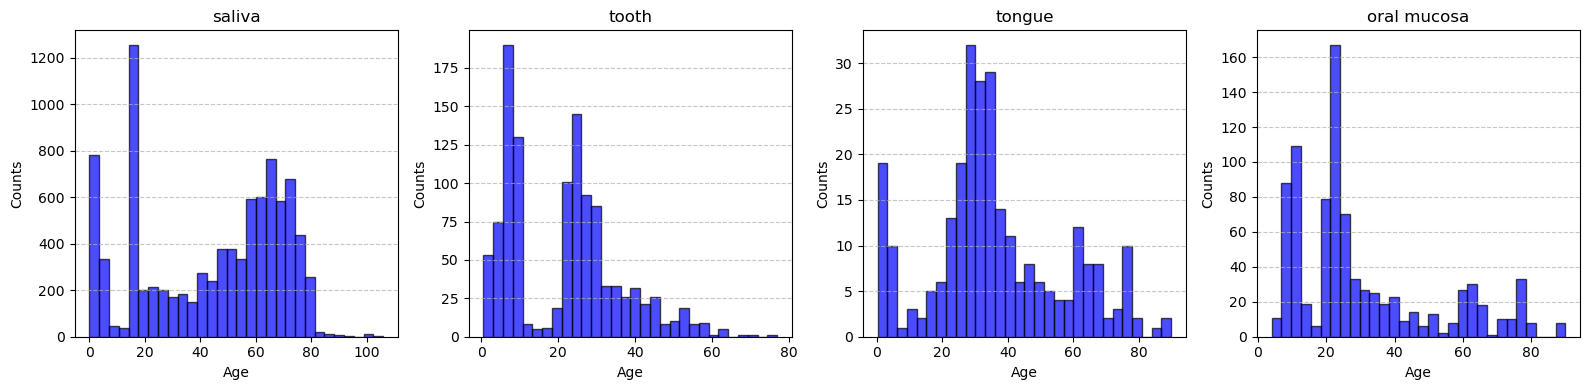

In [20]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']

fig, axes = plt.subplots(1, 4, figsize=(16, 4)) 

for i, site in enumerate(oral_sites):
    temp_site = temp.loc[temp.site_cleaned.values == site]
    
    axes[i].hist(temp_site.age_cleaned.values, bins=30, edgecolor='black', alpha=0.7, color='blue')
    axes[i].set_xlabel('Age')
    axes[i].set_ylabel('Counts')
    axes[i].set_title(site)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Study selection per site

For each oral site, keep only the studies (`bioproject_id`) that contribute **more than
10 healthy-control samples**, so every study entering cross-validation has enough
samples to be meaningful.

In [21]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
for i in oral_sites:
    temp = metadata.loc[metadata.status_cleaned == "HC"]
    temp = temp.loc[temp.site_cleaned.values == i]
    counts = temp.groupby('bioproject_id')['sample_id'].count()
    selected = counts[counts > 10]
    print(len(selected))

49
12
4
5
2
1


### RF difference sites

## Cross-validation: leave-studies-out

The most important design choice is **how the data is split**. Instead of splitting
individual samples at random, I split at the level of **studies (bioprojects)**. Samples
from the same study share sequencing batch, protocol, and cohort characteristics; a
random sample-level split would let the model memorize study-specific signatures and
report over-optimistic accuracy.

For each oral site independently:

1. Collect the qualifying studies for that site.
2. Run K-fold cross-validation over the **studies** (`KFold`, shuffled,
   `random_state=42`), with folds tuned per site.
3. In each fold, some studies form the training set and the held-out studies form the
   test set — so the model is always evaluated on studies it has never seen.

Within each fold:

- The **training set** uses only healthy-control samples from the training studies.
- The **test set** is restricted to the age range seen in training (samples outside it
  are removed) to avoid extrapolation. Folds whose test set becomes empty are skipped.

**Per-fold feature processing:** subset the table to training samples and drop absent
features (this defines the feature vocabulary); subset the test table to the same
features; **normalize to relative abundance** so sequencing depth doesn't dominate;
**align feature columns** by reindexing the test matrix to the training columns (missing
features filled with 0); and align age labels to the exact row order.

**Model:** a **Random Forest regressor** with 500 trees (`n_estimators=500`),
`random_state=42` for reproducibility, and `n_jobs=-1`. For each site/fold I save
per-sample results (sample id, true age, predicted age, error) plus a summary table of
split sizes.

In [22]:
EPS = 1e-6

In [23]:
OUTPUT_DIR = "../../data/age_prediction/leave_studies_out_rf"

In [24]:
# =====================================================================
# ADULT AGE-BAND re-run (18-65): restrict every site to a common age
# band so the train/test age distributions are comparable, then repeat
# the cross-study vs within-study comparison.
#   Primary metrics: MAE and Spearman rho (rank correlation).
#   R2 is shown only for reference (per-study R2 is unstable on narrow
#   ranges, so its MEDIAN is reported).
# Question answered: once the extreme age-distribution shift is removed,
# does the signal transfer across studies (cross ~ within), or does it
# still collapse (batch effect independent of age shift)?
# Reuses `table` and `metadata` already in memory. Lower N_TREES to speed up.
# =====================================================================
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

N_TREES          = 500
MIN_HC           = 10              # keep studies with > MIN_HC HC samples IN the band
band_sites       = ['saliva', 'tooth', 'tongue', 'oral mucosa']
band_folds       = {'saliva': 5, 'tooth': 5, 'tongue': 4, 'oral mucosa': 5}
site_age_range = {"saliva":[1, 80], "tooth": [1, 60], "tongue": [1, 80], 'oral mucosa': [1, 80]}
sid_to_age = metadata.set_index('sample_id')['age_cleaned']


def build_xy(md_tr, md_te):
    """Relative-abundance features; vocabulary from TRAIN only; test reindexed."""
    tr_t = table.filter(md_tr.sample_id.values, inplace=False).remove_empty(inplace=False)
    keep = tr_t.ids(axis='observation')
    te_t = table.filter(md_te.sample_id.values, inplace=False)
    te_t = te_t.filter(keep, axis='observation', inplace=False)
    Xtr = tr_t.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
    Xte = te_t.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
    Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)
    ytr = sid_to_age.reindex(Xtr.index).values.astype(float)
    yte = sid_to_age.reindex(Xte.index).values.astype(float)
    return np.log10(Xtr.values + EPS), ytr, np.log10(Xte.values + EPS), yte


def eval_fold(md_tr, md_te):
    """Train RF on md_tr, evaluate on md_te + mean-age baseline.
    No extra age-range restriction: the band already makes ranges comparable."""
    if md_tr.shape[0] < 5 or md_te.shape[0] < 2:
        return None
    Xtr, ytr, Xte, yte = build_xy(md_tr, md_te)
    rf = RandomForestRegressor(n_estimators=N_TREES, random_state=42, n_jobs=-1, 
                               max_features='sqrt', min_samples_leaf=2,)
    rf.fit(Xtr, ytr)
    pred = rf.predict(Xte)
    
    base = np.full_like(yte, ytr.mean())
    rho  = spearmanr(yte, pred)[0] if len(np.unique(yte)) > 1 else np.nan
    return dict(n_train=len(ytr), n_test=len(yte),
                model_R2=r2_score(yte, pred), model_MAE=mean_absolute_error(yte, pred),
                spearman=rho, base_MAE=mean_absolute_error(yte, base))


rows = []
for site in band_sites:
    AGE_MIN, AGE_MAX = site_age_range[site]
    md_site = metadata.loc[(metadata.site_cleaned == site) &
                           (metadata.status_cleaned == "HC") &
                           (metadata.age_cleaned > AGE_MIN) &
                           (metadata.age_cleaned <= AGE_MAX)]
    counts   = md_site.groupby('bioproject_id')['sample_id'].count()
    selected = counts[counts > MIN_HC].index.values
    pool     = md_site.loc[md_site.bioproject_id.isin(selected)].copy()
    studies  = pool.bioproject_id.unique()

    if len(studies) <= 3:
        print(f"[skip] {site}: only {len(studies)} study(ies) in "
              f"{AGE_MIN}-{AGE_MAX} with >{MIN_HC} HC samples")
        continue

    k = min(band_folds[site], len(studies))   # avoid n_splits > n_studies

    # (A) cross-study: hold out whole studies
    for fold, (tri, tei) in enumerate(
            KFold(k, shuffle=True, random_state=42).split(studies), 1):
        md_tr = pool.loc[pool.bioproject_id.isin(studies[tri])]
        md_te = pool.loc[pool.bioproject_id.isin(studies[tei])]
        r = eval_fold(md_tr, md_te)
        if r:
            rows.append(dict(site=site, scheme='cross_study', fold=fold, **r))

    # (B) within-study: random sample split (studies mixed)
    ids = pool.sample_id.values
    for fold, (tri, tei) in enumerate(
            KFold(k, shuffle=True, random_state=42).split(ids), 1):
        md_tr = pool.loc[pool.sample_id.isin(ids[tri])]
        md_te = pool.loc[pool.sample_id.isin(ids[tei])]
        r = eval_fold(md_tr, md_te)
        if r:
            rows.append(dict(site=site, scheme='within_study', fold=fold, **r))

    print(f"[done] {site}: {len(studies)} studies, "
          f"{pool.shape[0]} HC samples in {AGE_MIN}-{AGE_MAX}")

band = pd.DataFrame(rows)
band.to_csv("within_cross_results.csv")

[done] saliva: 49 studies, 8644 HC samples in 1-80


[done] tooth: 12 studies, 1076 HC samples in 1-60


[done] tongue: 4 studies, 201 HC samples in 1-80


[done] oral mucosa: 5 studies, 832 HC samples in 1-80


In [25]:
band = pd.read_csv("within_cross_results.csv")
band['beats_base'] = band['model_MAE'] < band['base_MAE']
pd.set_option('display.width', 175)
print(f"\n=== PER-FOLD ({AGE_MIN}-{AGE_MAX}) ===")
print(band.round(3).to_string(index=False))

summary = (band.groupby(['site', 'scheme'])
           .agg(folds         = ('fold', 'count'),
                MAE_mean      = ('model_MAE', 'mean'),
                MAE_sd        = ('model_MAE', 'std'),
                baseMAE       = ('base_MAE', 'mean'),
                spearman_mean = ('spearman', 'mean'),
                R2_median     = ('model_R2', 'median'),
                beats_base    = ('beats_base', 'mean'))
           .reset_index())
print(f"\n=== SUMMARY ({AGE_MIN}-{AGE_MAX}) — MAE & Spearman are primary ===")
print(summary.round(3).to_string(index=False))

# --- verdict: compare within vs cross on Spearman (robust) and MAE --------
sp  = band.groupby(['site', 'scheme'])['spearman'].mean().unstack('scheme')
mae = band.groupby(['site', 'scheme'])['model_MAE'].mean().unstack('scheme')

for site in band_sites:
    if site not in sp.index:
        continue
    ws, cs = sp.loc[site].get('within_study', np.nan),  sp.loc[site].get('cross_study', np.nan)
    wm, cm = mae.loc[site].get('within_study', np.nan), mae.loc[site].get('cross_study', np.nan)
    if pd.notna(cs) and cs >= 0.5 and pd.notna(cm) and pd.notna(wm) and cm <= 1.5 * wm:
        v = "signal now TRANSFERS reasonably (band restriction helped)"
    elif pd.notna(cs) and cs >= 0.3:
        v = "partial transfer — improved but still a gap"
    else:
        v = "still does NOT transfer (batch effect independent of age shift)"
    print(f"{site:12s} Spearman within={ws:+.2f} cross={cs:+.2f} | "
          f"MAE within={wm:.1f} cross={cm:.1f}  ->  {v}")

print("\nFor reference, ALL-AGE cross_study MAE from the diagnostic:")
print("  saliva 18.9 | tooth 9.6 | tongue 21.2 | oral mucosa 21.1")


=== PER-FOLD (1-80) ===
 Unnamed: 0        site       scheme  fold  n_train  n_test  model_R2  model_MAE  spearman  base_MAE  beats_base
          0      saliva  cross_study     1     7900     744     0.078     18.405     0.609    25.314        True
          1      saliva  cross_study     2     5043    3601    -2.481     23.636     0.250    30.541        True
          2      saliva  cross_study     3     7652     992     0.492     14.593     0.752    23.826        True
          3      saliva  cross_study     4     6271    2373     0.090     17.254     0.645    25.621        True
          4      saliva  cross_study     5     7710     934     0.234     16.204     0.544    19.130        True
          5      saliva within_study     1     6915    1729     0.773      9.285     0.842    21.463        True
          6      saliva within_study     2     6915    1729     0.770      9.452     0.836    21.769        True
          7      saliva within_study     3     6915    1729     0.732  

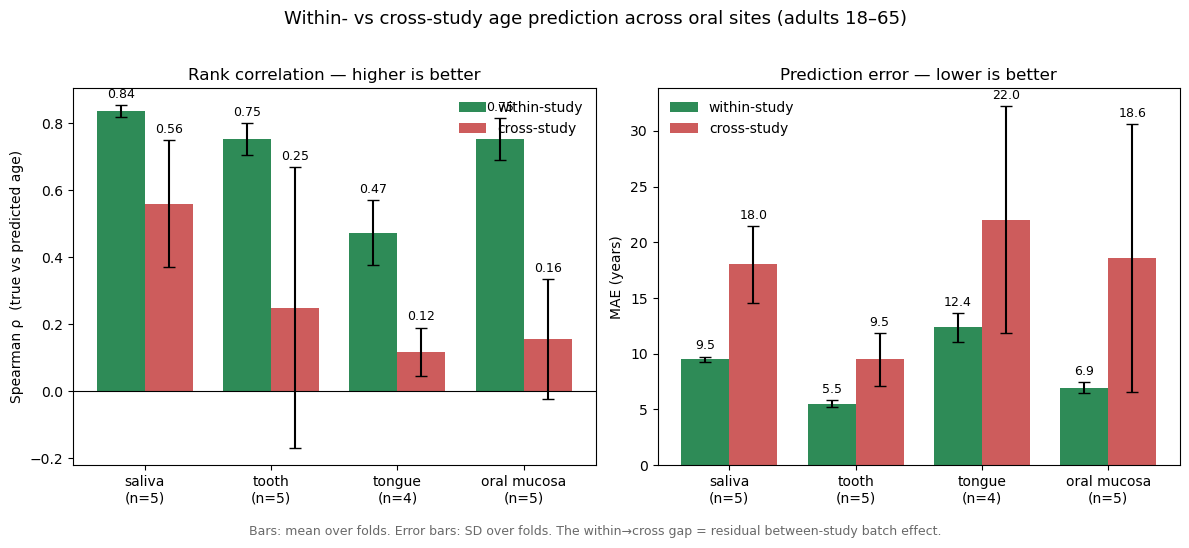

In [26]:
# =====================================================================
# PLOT: within- vs cross-study performance across oral sites (18-65).
#   Left  = Spearman rho  (higher is better; 0 line marked)
#   Right = MAE in years  (lower is better)
# Bars = mean over folds; error bars = SD over folds. The within/cross
# GAP is the batch-effect penalty remaining after the age-band fix.
# (n=...) under each site = number of cross-study folds (~studies): the
# smaller it is, the less reliable the cross-study bar.
# Uses the `band` DataFrame produced by the 18-65 age-band cell above.
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

assert 'band' in globals() and not band.empty, "Run the 18-65 age-band cell first."

site_order = ['saliva', 'tooth', 'tongue', 'oral mucosa']
sites = [s for s in site_order if s in band['site'].unique()]

def agg(metric):
    g  = band.groupby(['site', 'scheme'])[metric]
    m  = g.mean().unstack('scheme').reindex(sites)
    sd = g.std().unstack('scheme').reindex(sites)
    return m, sd

sp_m,  sp_sd  = agg('spearman')
mae_m, mae_sd = agg('model_MAE')

# number of cross-study folds per site (reliability flag)
nfold = (band[band.scheme == 'cross_study']
         .groupby('site')['fold'].count().reindex(sites).fillna(0).astype(int))
xlabels = [f"{s}\n(n={nfold[s]})" for s in sites]

x = np.arange(len(sites)); w = 0.38
C_within, C_cross = 'seagreen', 'indianred'

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# --- Spearman (higher better) ---
b1 = ax[0].bar(x - w/2, sp_m['within_study'], w, yerr=sp_sd['within_study'],
               capsize=4, color=C_within, label='within-study')
b2 = ax[0].bar(x + w/2, sp_m['cross_study'],  w, yerr=sp_sd['cross_study'],
               capsize=4, color=C_cross,  label='cross-study')
ax[0].axhline(0, color='k', lw=0.8)
ax[0].set_ylabel('Spearman ρ  (true vs predicted age)')
ax[0].set_title('Rank correlation — higher is better')
ax[0].set_xticks(x); ax[0].set_xticklabels(xlabels)
ax[0].bar_label(b1, fmt='%.2f', padding=3, fontsize=9)
ax[0].bar_label(b2, fmt='%.2f', padding=3, fontsize=9)
ax[0].legend(frameon=False, loc='upper right')

# --- MAE (lower better) ---
b3 = ax[1].bar(x - w/2, mae_m['within_study'], w, yerr=mae_sd['within_study'],
               capsize=4, color=C_within, label='within-study')
b4 = ax[1].bar(x + w/2, mae_m['cross_study'],  w, yerr=mae_sd['cross_study'],
               capsize=4, color=C_cross,  label='cross-study')
ax[1].set_ylabel('MAE (years)')
ax[1].set_title('Prediction error — lower is better')
ax[1].set_xticks(x); ax[1].set_xticklabels(xlabels)
ax[1].bar_label(b3, fmt='%.1f', padding=3, fontsize=9)
ax[1].bar_label(b4, fmt='%.1f', padding=3, fontsize=9)
ax[1].legend(frameon=False, loc='upper left')

fig.suptitle('Within- vs cross-study age prediction across oral sites (adults 18–65)',
             fontsize=13, y=1.02)
fig.text(0.5, -0.03, 'Bars: mean over folds. Error bars: SD over folds. '
         'The within→cross gap = residual between-study batch effect.',
         ha='center', fontsize=9, color='dimgray')

plt.tight_layout()
plt.savefig('within_vs_cross_by_site.png', dpi=200, bbox_inches='tight')
plt.show()

In [27]:
# =====================================================================
# SCATTER: saliva only — true vs predicted age (adults 18-65).
# The band cell stored only per-fold metrics, so this re-runs the saliva
# CV and collects per-sample out-of-fold predictions, then plots them.
# Set SCHEME to 'cross_study' (leave-studies-out; honest generalization)
# or 'within_study' (random sample split). MAE and Spearman are pooled
# over all held-out saliva samples and annotated on the figure.
# Reuses `table` and `metadata` in memory. Lower N_TREES to speed up.
# =====================================================================
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr
import numpy as np
import matplotlib.pyplot as plt

SCHEME           = 'cross_study'   # 'cross_study' or 'within_study'
AGE_MIN, AGE_MAX = 1, 80
N_TREES          = 500
N_SPLITS         = 5
site             = 'saliva'

sid_to_age = metadata.set_index('sample_id')['age_cleaned']


def build_xy(md_tr, md_te):
    md_tr = md_tr.loc[md_tr.status_cleaned == "HC"]
    tr_t = table.filter(md_tr.sample_id.values, inplace=False).remove_empty(inplace=False)
    keep = tr_t.ids(axis='observation')
    te_t = table.filter(md_te.sample_id.values, inplace=False)
    te_t = te_t.filter(keep, axis='observation', inplace=False)
    Xtr = tr_t.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
    Xte = te_t.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
    Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)
    ytr = sid_to_age.reindex(Xtr.index).values.astype(float)
    yte = sid_to_age.reindex(Xte.index).values.astype(float)
    return np.log10(Xtr.values + EPS), ytr, np.log10(Xte.values + EPS), yte


# --- build the saliva 18-65 HC pool (same rule as the band cell) -------------
for site in band_sites:
    md_site = metadata.loc[(metadata.site_cleaned == site) &
                           # (metadata.status_cleaned == "HC") &
                           (metadata.age_cleaned >= AGE_MIN) &
                           (metadata.age_cleaned <= AGE_MAX)]
    counts   = md_site.groupby('bioproject_id')['sample_id'].count()
    selected = counts[counts > 10].index.values
    pool     = md_site.loc[md_site.bioproject_id.isin(selected)].copy()
    studies  = pool.bioproject_id.unique()
    k        = min(N_SPLITS, len(studies))
    
    
    split_units = studies
    def subset(units):
        return (pool.loc[pool.bioproject_id.isin(units[0])],
                pool.loc[pool.bioproject_id.isin(units[1])])
    
    
    true_all, pred_all = [], []
    fold = 1
    for tri, tei in KFold(k, shuffle=True, random_state=42).split(split_units):
        md_tr, md_te = subset((split_units[tri], split_units[tei]))
        if md_tr.shape[0] < 5 or md_te.shape[0] < 2:
            continue
        Xtr, ytr, Xte, yte = build_xy(md_tr, md_te)
        rf = RandomForestRegressor(n_estimators=N_TREES, random_state=42, n_jobs=-1, 
                                   max_features='sqrt', min_samples_leaf=2,)
        rf.fit(Xtr, ytr)
        true_all.append(yte)
        pred_all.append(rf.predict(Xte))
        print(f"spearmanr: {spearmanr(yte, rf.predict(Xte))[0]}")
        result_df = pd.DataFrame({
                'sample_id': md_te.sample_id.values,
                'true_age':  yte,
                'pred_age':  rf.predict(Xte)
            })
        result_df.to_csv(
            f"{OUTPUT_DIR}/age_predict_test_{fold}_{site}_genus_range_1_80.csv", index=False
        )
        fold = fold + 1

spearmanr: 0.4184951503363007


spearmanr: 0.5132519601521712


spearmanr: 0.7628368547228923


spearmanr: 0.6278454283985682


spearmanr: 0.2916992535084521


...

spearmanr: 0.45082279539566866


spearmanr: 0.6010262403490757


spearmanr: 0.20122208782024534


spearmanr: 0.2353914775296946


spearmanr: 0.06969133733903114


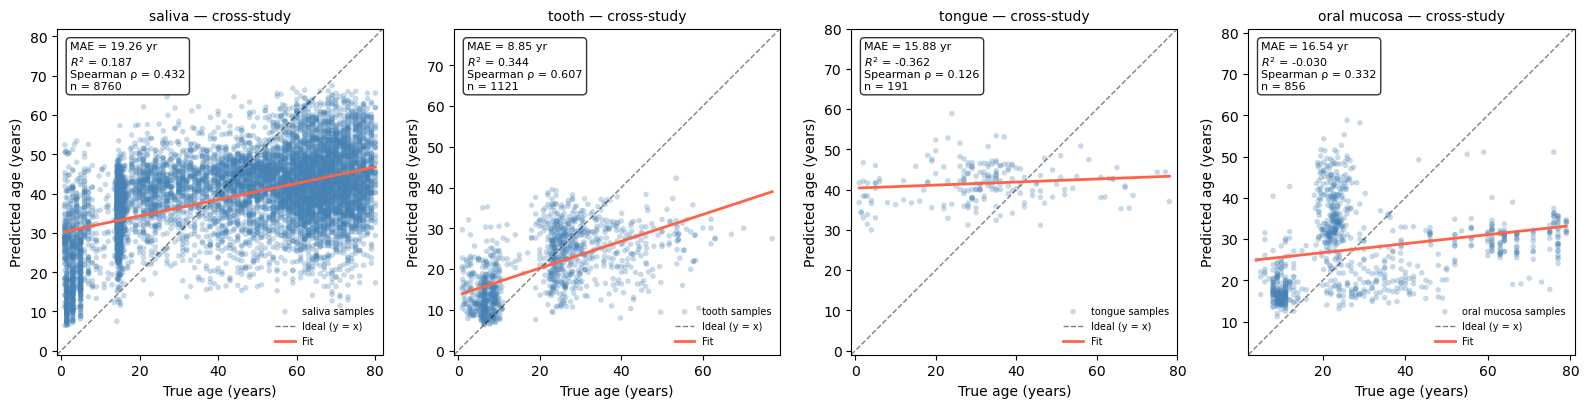

In [28]:
sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))  

for ax, site in zip(axes.ravel(), sites):
    n_rep = 4 if site == "tongue" else 5
    dfs = [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{site}_genus_range_1_80.csv")
           for i in range(1, n_rep + 1)]
    site_df = pd.concat(dfs, ignore_index=True)
    site_df = site_df.merge(metadata, on='sample_id', how='inner')
    site_df = site_df.loc[site_df.status_cleaned == "HC"]

    true_all = site_df.true_age.values
    pred_all = site_df.pred_age.values
    if len(true_all) == 0:
        ax.set_axis_off()
        ax.set_title(f"{site} — no data")
        continue

    mae = mean_absolute_error(true_all, pred_all)
    r2  = r2_score(true_all, pred_all)          
    rho = spearmanr(true_all, pred_all)[0]

    ax.scatter(true_all, pred_all, alpha=0.30, s=16, color='steelblue',
               edgecolor='none', label=f'{site} samples')

    lo = min(true_all.min(), pred_all.min()) - 2
    hi = max(true_all.max(), pred_all.max()) + 2
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, alpha=0.5, label='Ideal (y = x)')

    z = np.polyfit(true_all, pred_all, 1)
    xl = np.linspace(true_all.min(), true_all.max(), 100)
    ax.plot(xl, np.poly1d(z)(xl), color='tomato', lw=2, label='Fit')

    ax.text(0.04, 0.96,
            f"MAE = {mae:.2f} yr\n$R^2$ = {r2:.3f}\nSpearman ρ = {rho:.3f}\nn = {len(true_all)}",
            transform=ax.transAxes, va='top', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.35', facecolor='white', alpha=0.8))

    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_xlabel('True age (years)')
    ax.set_ylabel('Predicted age (years)')
    ax.set_title(f"{site} — {SCHEME.replace('_', '-')}", fontsize=10)
    ax.legend(loc='lower right', frameon=False, fontsize=7)

fig.tight_layout()
plt.show()

### Health and disease

In [29]:
metadata = metadata.loc[metadata['status_cleaned'].notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [30]:
metadata.status_cleaned.unique()

array(['HC', 'IBD', 'HIV', 'ICU discharge or on ICU day 10', 'ICU',
       'Obesity', 'OSCC', 'Atopic Dermatitis', 'Chagas Disease',
       'Oral Submucous Fibrosis', 'Oral Mucositis',
       'Oral Verrucous Hyperplasia', 'Preterm', 'Periodontal Disease',
       'Dental Caries', 'Oral Lichen Planus', 'Celiac Disease',
       "Sjögren's Syndrome", 'Aphthous',
       'Gastroesophageal Reflux Disease', 'Head and Neck Cancer',
       'COVID-19', 'Lung Cancer', 'Colorectal Cancer',
       'Axial Spondyloarthritis', 'Depression'], dtype=object)

In [31]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
site_dfs = {}
for j in oral_sites:
    site_tag = j.replace(' ', '_')
    n_rep = 4 if j == "tongue" else 5
    dfs = [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{j}_genus_range_1_80.csv")
           for i in range(1, n_rep + 1)]
    site_dfs[j] = pd.concat(dfs, ignore_index=True).set_index("sample_id")

In [32]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import mannwhitneyu

MIN_N = 10         
N_BOOT = 2000

def bh_fdr(p):
    p = np.asarray(p, float); n = len(p)
    o = np.argsort(p)
    r = p[o] * n / np.arange(1, n + 1)
    r = np.minimum.accumulate(r[::-1])[::-1]
    out = np.empty(n); out[o] = np.clip(r, 0, 1)
    return out

def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    gt = sum(np.sum(x > b) for x in a)
    lt = sum(np.sum(x < b) for x in a)
    return (gt - lt) / (len(a) * len(b))

def boot_ci_median_diff(dis, hc, rng, n_boot=N_BOOT):
    d = np.array([np.median(rng.choice(dis, len(dis), True)) -
                  np.median(rng.choice(hc,  len(hc),  True)) for _ in range(n_boot)])
    return np.percentile(d, [2.5, 97.5])

rng = np.random.default_rng(0)
long_rows, stat_rows = [], []

for j in oral_sites:
    meta_pick = metadata.loc[metadata.site_cleaned == j].set_index("sample_id")
    meta_pick.index = meta_pick.index.astype(str)
    site_dfs[j].index = site_dfs[j].index.astype(str)
    sid = np.intersect1d(meta_pick.index.values, site_dfs[j].index.values)

    df = site_dfs[j].loc[sid].copy()
    df["status"] = meta_pick.loc[sid, "status_cleaned"].values
    df["delta_age"] = df.pred_age.values - df.true_age.values
    df["site"] = j

    counts = df["status"].value_counts()
    keep = [s for s in counts.index if s == "HC" or counts[s] >= MIN_N]
    dropped = {s: int(counts[s]) for s in counts.index if s not in keep}
    if dropped:
        print(f"[{j}] delect n<{MIN_N} : {dropped}")
    df = df[df["status"].isin(keep)]
    long_rows.append(df)

    hc = df.loc[df.status == "HC", "delta_age"].values
    recs = []
    for s in [x for x in keep if x != "HC"]:
        v = df.loc[df.status == s, "delta_age"].values
        p = mannwhitneyu(v, hc, alternative="two-sided")[1]
        lo, hi = boot_ci_median_diff(v, hc, rng)
        recs.append(dict(site=j, status=s, n=len(v),
                         med=np.median(v),
                         delta=np.median(v) - np.median(hc),
                         ci_lo=lo, ci_hi=hi,
                         cliff=cliffs_delta(v, hc), p=p))
    if recs:
        r = pd.DataFrame(recs)
        r["fdr"] = bh_fdr(r["p"].values)          
        r["hc_med"] = np.median(hc)
        r["hc_n"] = len(hc)
        stat_rows.append(r)

long_df = pd.concat(long_rows, ignore_index=True)
stats   = pd.concat(stat_rows, ignore_index=True)

def stars(q):
    return "***" if q < .001 else "**" if q < .01 else "*" if q < .05 else "ns"
stats["sig"] = stats["fdr"].map(stars)

[saliva] delect n<10 : {'ICU discharge or on ICU day 10': 9, 'Aphthous': 3}


[tooth] delect n<10 : {"Sjögren's Syndrome": 9}


[tongue] delect n<10 : {'OSCC': 8}


[oral mucosa] delect n<10 : {'OSCC': 5, 'Oral Mucositis': 3}


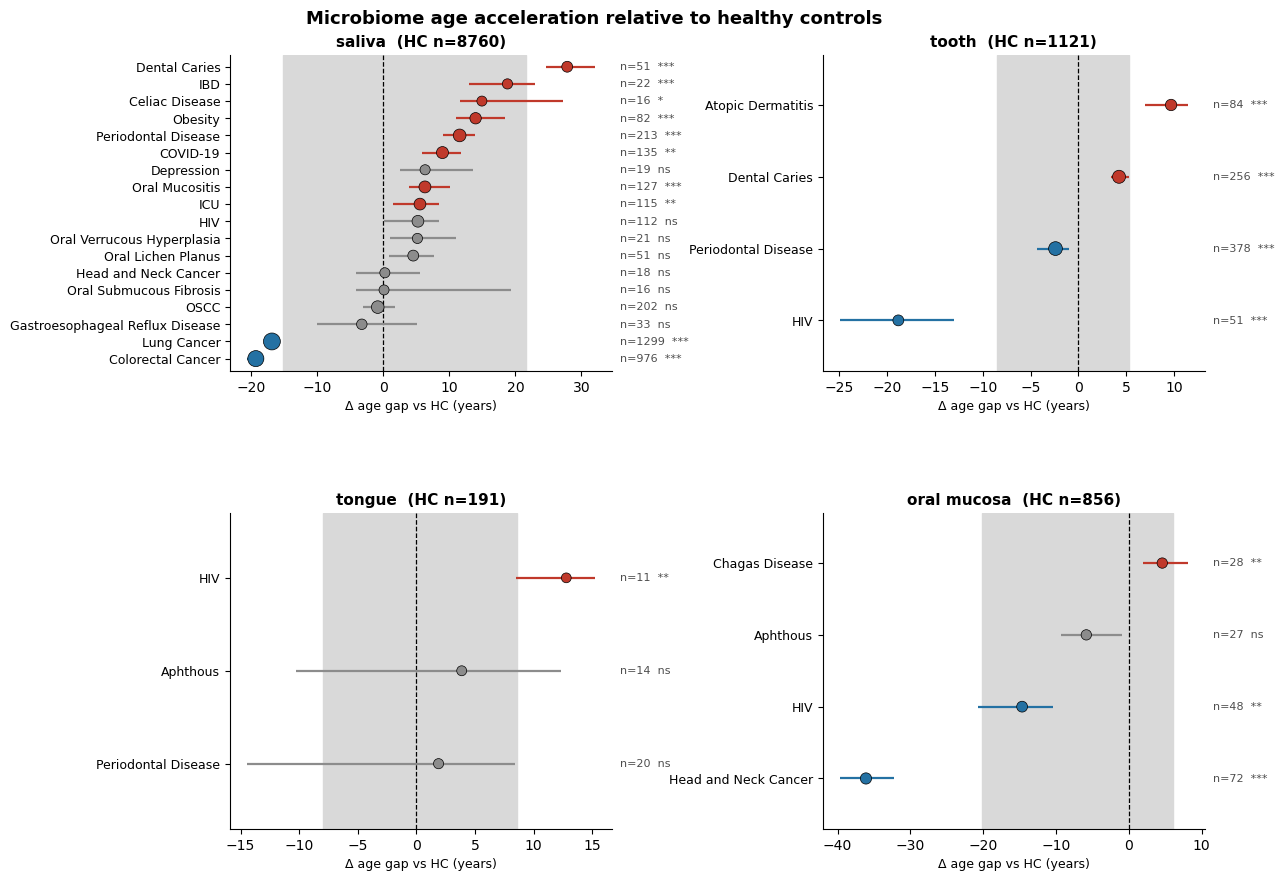

In [33]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
fig = plt.figure(figsize=(13, 9))
gs  = GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.55,
               left=0.22, right=0.97, top=0.93, bottom=0.07)

for idx, j in enumerate(oral_sites):
    ax = fig.add_subplot(gs[divmod(idx, 2)])
    s = stats[stats.site == j].sort_values("delta")
    if len(s) == 0:
        ax.set_axis_off(); ax.set_title(f"{j} — no data"); continue

    hc_v = long_df.loc[(long_df.site == j) & (long_df.status == "HC"), "delta_age"]
    q1, q3 = np.percentile(hc_v, [25, 75])
    ax.axvspan(q1 - np.median(hc_v), q3 - np.median(hc_v),
               color="0.85", zorder=0, label="HC IQR")
    ax.axvline(0, color="k", ls="--", lw=0.9, zorder=1)

    y = np.arange(len(s))
    col = np.where(s.fdr < .05, np.where(s.delta > 0, "#c0392b", "#2471a3"), "0.55")
    ax.hlines(y, s.ci_lo, s.ci_hi, color=col, lw=1.6, zorder=2)
    ax.scatter(s.delta, y, s=40 + 3 * np.sqrt(s.n), c=col,
               edgecolor="k", lw=.5, zorder=3)

    for yi, row in zip(y, s.itertuples()):
        ax.text(1.02, yi, f"n={row.n}  {row.sig}", transform=ax.get_yaxis_transform(),
                va="center", fontsize=8, color="0.3")

    ax.set_yticks(y); ax.set_yticklabels(s.status, fontsize=9)
    ax.set_ylim(-0.7, len(s) - 0.3)
    ax.set_xlabel("Δ age gap vs HC (years)", fontsize=9)
    ax.set_title(f"{j}  (HC n={int(s.hc_n.iloc[0])})", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Microbiome age acceleration relative to healthy controls",
             fontsize=13, fontweight="bold")
plt.show()

In [35]:
for j in oral_sites:
    hc = long_df[(long_df.site==j) & (long_df.status=='HC')]
    a, b = np.polyfit(hc.true_age, hc.pred_age, 1)
    print(f"{j:12s} n={len(hc):5d}  R2={r2_score(hc.true_age, hc.pred_age):+.3f}  "
          f"ρ={spearmanr(hc.true_age, hc.pred_age)[0]:.3f}  α={a:.3f}  MAE={mean_absolute_error(hc.true_age, hc.pred_age):.1f}")

saliva       n= 8760  R2=+0.187  ρ=0.432  α=0.208  MAE=19.3
tooth        n= 1121  R2=+0.344  ρ=0.607  α=0.329  MAE=8.8
tongue       n=  191  R2=-0.362  ρ=0.126  α=0.038  MAE=15.9
oral mucosa  n=  856  R2=-0.030  ρ=0.332  α=0.109  MAE=16.5


In [37]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import r2_score, mean_absolute_error

MIN_N = 10
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']

meta_u = metadata.drop_duplicates('sample_id').set_index('sample_id')
meta_u.index = meta_u.index.astype(str)

rows = []
for j in oral_sites:
    n_rep = 4 if j == "tongue" else 5
    df = pd.concat(
        [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{j}_genus_range_1_80.csv")
         for i in range(1, n_rep + 1)], ignore_index=True)

    df['sample_id'] = df.sample_id.astype(str)
    df = df.drop_duplicates('sample_id')
    df = df[df.sample_id.isin(meta_u.index)].copy()

    df['site']       = j
    df['status']     = meta_u.loc[df.sample_id, 'status_cleaned'].values
    df['bioproject'] = meta_u.loc[df.sample_id, 'bioproject_id'].values   # ← 关键
    df['delta_age']  = df.pred_age.values - df.true_age.values

    cnt  = df.status.value_counts()
    keep = [s for s in cnt.index if s == 'HC' or cnt[s] >= MIN_N]
    rows.append(df[df.status.isin(keep)])

long_df = pd.concat(rows, ignore_index=True)

In [583]:
def matched_beta(gd, gh, tol=2, n_rep=200, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_rep):
        pool, pairs = gh.copy(), []
        for a, dg in zip(gd.true_age.values, gd.delta_age.values):
            c = pool.index[np.abs(pool.true_age - a) <= tol]
            if len(c) == 0: continue
            k = rng.choice(c); pairs.append(dg - pool.loc[k, 'delta_age'])
            pool = pool.drop(k)
        if len(pairs) >= 10: out.append(np.median(pairs))
    return (np.median(out), *np.percentile(out, [2.5, 97.5]), len(out)) if out else (np.nan,)*4

for j, s, bp in [('tooth','Periodontal Disease','PRJEB50261'),
                 ('saliva','Lung Cancer','PRJNA801882'),
                 ('saliva','Colorectal Cancer','PRJNA801882')]:   # CRC 作阴性对照
    gd = long_df[(long_df.site==j)&(long_df.status==s)&(long_df.bioproject==bp)]
    gh = long_df[(long_df.site==j)&(long_df.status=='HC')&(long_df.bioproject==bp)]
    b, lo, hi, k = matched_beta(gd, gh)
    print(f"{j:8s} {s:22s} 匹配 β={b:+.1f} [{lo:+.1f},{hi:+.1f}]  ({k} 次重复)")

tooth    Periodontal Disease    匹配 β=+7.1 [+6.1,+7.9]  (200 次重复)
saliva   Lung Cancer            匹配 β=+3.1 [+2.6,+3.8]  (200 次重复)
saliva   Colorectal Cancer      匹配 β=-0.4 [-1.2,+0.5]  (200 次重复)


In [584]:
def null_beta(gh, n_perm=500, seed=0):
    """把 HC 随机劈成两半当伪 case/control，跑同样的 ANCOVA → β 的零分布"""
    rng = np.random.default_rng(seed); out = []
    for _ in range(n_perm):
        idx = rng.permutation(len(gh)); h = len(gh)//2
        A, B = gh.iloc[idx[:h]], gh.iloc[idx[h:]]
        b1, b0 = np.polyfit(B.true_age, B.delta_age, 1)
        out.append(np.median(A.delta_age - (b0 + b1*A.true_age)) -
                   np.median(B.delta_age - (b0 + b1*B.true_age)))
    return np.percentile(out, [2.5, 97.5]), np.std(out)

for j, bp in [('tooth','PRJEB50261'), ('saliva','PRJNA801882')]:
    gh = long_df[(long_df.site==j)&(long_df.status=='HC')&(long_df.bioproject==bp)]
    (lo, hi), sd = null_beta(gh)
    print(f"{j:8s} {bp:12s} HC 零分布 β 95% = [{lo:+.2f},{hi:+.2f}], SD={sd:.2f}")

tooth    PRJEB50261   HC 零分布 β 95% = [-1.59,+1.84], SD=0.86
saliva   PRJNA801882  HC 零分布 β 95% = [-0.65,+0.58], SD=0.31


In [600]:
# =====================================================================
# Figure 1-4  for the microbiome-age artifact paper
# =====================================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import spearmanr

oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
MIN_BP_N, MIN_BP_SD = 20, 3.0   

import os; os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 8, 'axes.linewidth': .6, 'font.family': 'DejaVu Sans',
    'xtick.major.width': .6, 'ytick.major.width': .6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
C_HC, C_UP, C_DN, C_NS = '#5F5E5A', '#A32D2D', '#185FA5', '#B4B2A9'

hc_all = long_df[long_df.status == 'HC'].copy()

[Fig1] 41 projects | median slope = -0.944 IQR = [-0.99, -0.86] | alpha = 0.056


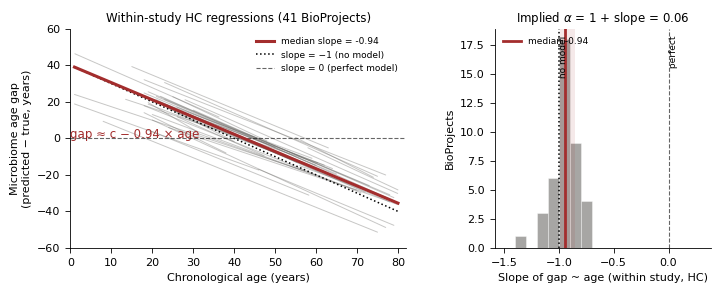

In [601]:
# =====================================================================
# FIG 1 | 伪影的定律：27 个项目 HC 内 gap ~ age 斜率 = -0.88
# =====================================================================
slopes = []
for (site, bp), g in hc_all.groupby(['site', 'bioproject']):
    if len(g) < MIN_BP_N or g.true_age.std() < MIN_BP_SD:
        continue
    b1, b0 = np.polyfit(g.true_age, g.delta_age, 1)
    slopes.append(dict(site=site, bp=bp, n=len(g), b1=b1, b0=b0,
                       lo=g.true_age.min(), hi=g.true_age.max()))
SL = pd.DataFrame(slopes)
print(f"[Fig1] {len(SL)} projects | median slope = {SL.b1.median():.3f} "
      f"IQR = [{SL.b1.quantile(.25):.2f}, {SL.b1.quantile(.75):.2f}] "
      f"| alpha = {1 + SL.b1.median():.3f}")
SL.to_csv(f"{FIG_DIR}/Fig1_slopes.csv", index=False)

fig = plt.figure(figsize=(7.2, 3.0))
gs  = GridSpec(1, 2, width_ratios=[1.55, 1], wspace=.32,
               left=.09, right=.98, top=.90, bottom=.17)

ax = fig.add_subplot(gs[0])
for r in SL.itertuples():                             
    xx = np.linspace(r.lo, r.hi, 2)
    ax.plot(xx, r.b0 + r.b1 * xx, color=C_HC, lw=.7, alpha=.35, solid_capstyle='round')
med, b0m = SL.b1.median(), np.median(SL.b0)
xx = np.array([1., 80.])
ax.plot(xx, b0m + med * xx, color=C_UP, lw=2.2, zorder=5, label=f'median slope = {med:.2f}')
ax.plot(xx, b0m + (-1.) * xx, color='k', ls=':', lw=1.1, zorder=4, label='slope = \u22121 (no model)')
ax.axhline(0, color='k', ls='--', lw=.8, alpha=.6, zorder=4, label='slope = 0 (perfect model)')
ax.set_xlim(0, 82); ax.set_ylim(-60, 60)
ax.set_xlabel('Chronological age (years)')
ax.set_ylabel('Microbiome age gap\n(predicted \u2212 true, years)')
ax.set_title(f'Within-study HC regressions ({len(SL)} BioProjects)', fontsize=8.5, pad=5)
ax.legend(loc='upper right', fontsize=6.5)
ax.text(.02, .05, f'gap \u2248 c \u2212 {abs(med):.2f} \u00d7 age',
        fontsize=8.5, color=C_UP)
ax = fig.add_subplot(gs[1])
b = SL.b1.values
ax.hist(b, bins=np.arange(-1.5, .35, .1), color=C_HC, alpha=.55, edgecolor='w', lw=.5)
ax.axvspan(np.percentile(b, 25), np.percentile(b, 75), color=C_UP, alpha=.10, lw=0)
ax.axvline(np.median(b), color=C_UP, lw=2, label=f'median {np.median(b):.2f}')
ax.axvline(-1, color='k', ls=':', lw=1.1)
ax.axvline(0, color='k', ls='--', lw=.8, alpha=.6)
top = ax.get_ylim()[1]
ax.text(-1, top * .97, ' no model', fontsize=6.5, va='top', rotation=90)
ax.text(0,  top * .97, ' perfect',  fontsize=6.5, va='top', rotation=90)
ax.set_xlabel('Slope of gap ~ age (within study, HC)')
ax.set_ylabel('BioProjects')
ax.set_title(f'Implied $\\alpha$ = 1 + slope = {1 + np.median(b):.2f}', fontsize=8.5, pad=5)
ax.legend(loc='upper left', fontsize=6.5)

plt.show()

[Fig2]
           lab  overall  within     lo    hi  k  K
saliva\nchild    0.512     NaN    NaN   NaN  0  0
saliva\nadult    0.112   0.171  0.147 0.195 24 33
 tooth\nchild    0.089     NaN    NaN   NaN  0  0
 tooth\nadult    0.075   0.063 -0.019 0.144  1  4


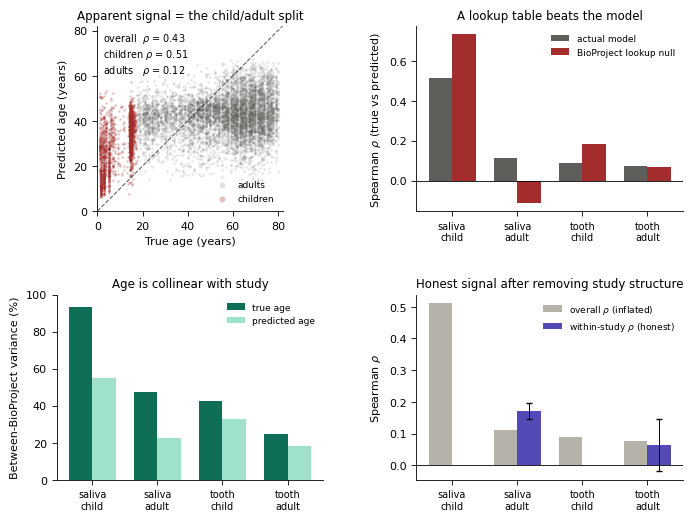

In [602]:
# =====================================================================
# FIG 2 | 表观性能从哪来
# =====================================================================
def _band(site, lo, hi):
    return hc_all[(hc_all.site == site) & (hc_all.true_age >= lo) & (hc_all.true_age < hi)]

def lookup_rho(site, lo, hi):
    """真实模型 rho  vs  「只输出该项目预测均值」的查表零模型 rho"""
    g = _band(site, lo, hi)
    if len(g) < 30: return np.nan, np.nan
    m = g.groupby('bioproject').pred_age.transform('mean')
    return spearmanr(g.true_age, g.pred_age)[0], spearmanr(g.true_age, m)[0]

def between_frac(site, lo, hi, col):
    g = _band(site, lo, hi)
    if len(g) < 30: return np.nan
    m = g.groupby('bioproject')[col].transform('mean')
    return ((m - g[col].mean()) ** 2).sum() / ((g[col] - g[col].mean()) ** 2).sum()

def meta_rho(df):
    """Fisher-z 加权合并项目内 rho"""
    rr = [(len(g), spearmanr(g.true_age, g.pred_age)[0])
          for _, g in df.groupby('bioproject')
          if len(g) >= MIN_BP_N and g.true_age.std() >= MIN_BP_SD]
    if len(rr) < 2: return (np.nan,) * 3 + (0, 0)
    n = np.array([x[0] for x in rr]); r = np.array([x[1] for x in rr])
    z, w = np.arctanh(np.clip(r, -.999, .999)), n - 3
    zb, se = np.average(z, weights=w), 1 / np.sqrt((n - 3).sum())
    return np.tanh(zb), np.tanh(zb - 1.96*se), np.tanh(zb + 1.96*se), int((r > 0).sum()), len(r)

cells = [('saliva', 1, 18, 'saliva\nchild'), ('saliva', 18, 80, 'saliva\nadult'),
         ('tooth', 1, 18, 'tooth\nchild'),   ('tooth', 18, 80, 'tooth\nadult')]
x, w = np.arange(len(cells)), .36

fig = plt.figure(figsize=(7.2, 5.4))
gs  = GridSpec(2, 2, hspace=.45, wspace=.35, left=.10, right=.97, top=.93, bottom=.09)

# (a) saliva 散点：儿童/成人分色
ax = fig.add_subplot(gs[0, 0])
g  = hc_all[hc_all.site == 'saliva']
ch, ad = g[g.true_age < 18], g[g.true_age >= 18]
ax.scatter(ad.true_age, ad.pred_age, s=3, alpha=.18, color=C_HC, lw=0, label='adults')
ax.scatter(ch.true_age, ch.pred_age, s=3, alpha=.30, color=C_UP, lw=0, label='children')
ax.plot([0, 82], [0, 82], 'k--', lw=.8, alpha=.6)
ax.set_xlim(0, 82); ax.set_ylim(0, 82); ax.set_aspect('equal')
ax.set_xlabel('True age (years)'); ax.set_ylabel('Predicted age (years)')
ax.set_title('Apparent signal = the child/adult split', fontsize=8.5, pad=5)
r_all = spearmanr(g.true_age, g.pred_age)[0]
r_ch  = spearmanr(ch.true_age, ch.pred_age)[0]
r_ad  = spearmanr(ad.true_age, ad.pred_age)[0]
ax.text(.03, .97, f"overall  $\\rho$ = {r_all:.2f}\nchildren $\\rho$ = {r_ch:.2f}\n"
                  f"adults   $\\rho$ = {r_ad:.2f}",
        transform=ax.transAxes, va='top', fontsize=7)
ax.legend(loc='lower right', fontsize=6.5, markerscale=2.5)

# (b) 查表零模型 vs 真实模型
ax  = fig.add_subplot(gs[0, 1])
act = [lookup_rho(s, l, h)[0] for s, l, h, _ in cells]
nul = [lookup_rho(s, l, h)[1] for s, l, h, _ in cells]
ax.bar(x - w/2, act, w, color=C_HC, label='actual model')
ax.bar(x + w/2, nul, w, color=C_UP, label='BioProject lookup null')
ax.axhline(0, color='k', lw=.6)
ax.set_xticks(x); ax.set_xticklabels([c[3] for c in cells], fontsize=7)
ax.set_ylabel('Spearman $\\rho$ (true vs predicted)')
ax.set_title('A lookup table beats the model', fontsize=8.5, pad=5)
ax.legend(fontsize=6.5, loc='upper right')

# (c) 年龄与项目的共线性
ax = fig.add_subplot(gs[1, 0])
ft = np.array([between_frac(s, l, h, 'true_age') for s, l, h, _ in cells]) * 100
fp = np.array([between_frac(s, l, h, 'pred_age') for s, l, h, _ in cells]) * 100
ax.bar(x - w/2, ft, w, color='#0F6E56', label='true age')
ax.bar(x + w/2, fp, w, color='#9FE1CB', label='predicted age')
ax.set_xticks(x); ax.set_xticklabels([c[3] for c in cells], fontsize=7)
ax.set_ylabel('Between-BioProject variance (%)'); ax.set_ylim(0, 100)
ax.set_title('Age is collinear with study', fontsize=8.5, pad=5)
ax.legend(fontsize=6.5)

# (d) 整体 rho（虚高） vs 项目内 rho（诚实）
ax, rows = fig.add_subplot(gs[1, 1]), []
for s, lo, hi, lab in cells:
    d = _band(s, lo, hi)
    m, l, u, k, K = meta_rho(d)
    rows.append((lab, spearmanr(d.true_age, d.pred_age)[0] if len(d) > 30 else np.nan,
                 m, l, u, k, K))
M  = pd.DataFrame(rows, columns=['lab', 'overall', 'within', 'lo', 'hi', 'k', 'K'])
err = np.vstack([(M.within - M.lo).fillna(0), (M.hi - M.within).fillna(0)])
ax.bar(x - w/2, M.overall, w, color=C_NS, label='overall $\\rho$ (inflated)')
ax.bar(x + w/2, M.within,  w, color='#534AB7', yerr=err, capsize=2,
       error_kw=dict(lw=.7), label='within-study $\\rho$ (honest)')
ax.axhline(0, color='k', lw=.6)
ax.set_xticks(x); ax.set_xticklabels(M.lab, fontsize=7)
ax.set_ylabel('Spearman $\\rho$')
ax.set_title('Honest signal after removing study structure', fontsize=8.5, pad=5)
ax.legend(fontsize=6.5)
print("[Fig2]\n", M.round(3).to_string(index=False))

plt.show()

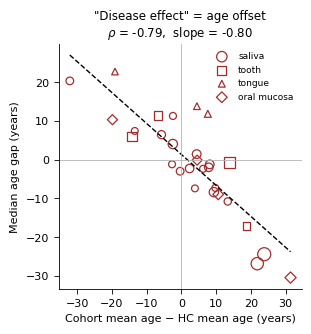

In [610]:
# =====================================================================
# FIG 3 | 伪影生成疾病"效应"
# =====================================================================
hc_ref = hc_all.groupby('site').true_age.mean()
D = (long_df[long_df.status != 'HC'].groupby(['site', 'status'])
     .agg(n=('true_age', 'size'), age_mean=('true_age', 'mean'),
          gap_med=('delta_age', 'median')).reset_index())
D['age_offset'] = D.age_mean - D.site.map(hc_ref)

fig = plt.figure(figsize=(7, 3.4))
gs  = GridSpec(1, 2, width_ratios=[1, 1.15], wspace=.36,
               left=.09, right=.97, top=.89, bottom=.17)

# (a) 疾病 gap vs 队列年龄偏移
ax = fig.add_subplot(gs[0])
mk = dict(zip(oral_sites, ['o', 's', '^', 'D']))
for s in oral_sites:
    d = D[D.site == s]
    if not len(d): continue
    ax.scatter(d.age_offset, d.gap_med, s=16 + 2*np.sqrt(d.n), marker=mk[s],
               facecolor='none', edgecolor=C_UP, lw=.9, label=s)
a, b0 = np.polyfit(D.age_offset, D.gap_med, 1)
xl = np.linspace(D.age_offset.min(), D.age_offset.max(), 20)
ax.plot(xl, a * xl + b0, 'k--', lw=1)
rho = spearmanr(D.age_offset, D.gap_med)[0]
ax.axhline(0, color='.7', lw=.6); ax.axvline(0, color='.7', lw=.6)
ax.set_xlabel('Cohort mean age \u2212 HC mean age (years)')
ax.set_ylabel('Median age gap (years)')
ax.set_title(f'"Disease effect" = age offset\n$\\rho$ = {rho:.2f},  slope = {a:.2f}',
             fontsize=8.5, pad=5)
ax.legend(fontsize=6.5, loc='upper right')

plt.show()